## Parte 1 ##

In [102]:
import numpy as np
import matplotlib.pyplot as plt

In [103]:
rng = np.random.default_rng(seed=22)

In [104]:
tiempo = np.linspace(0, 10, 500)
#colocamos el intervalo de tiempo

In [105]:
flujo = np.ones_like(tiempo)
#creamos una lista del mismo tamaño que el tiempo llena de 1

In [106]:
ruido = rng.normal(loc=0.0, scale=0.002, size=len(tiempo))
#agregamos al flujo ruido gaussiano con una desviación de 0.002

In [107]:
flujo = flujo + ruido

In [108]:
transito1 = (tiempo >= 4.5) & (tiempo <= 5.0)
transito2 = (tiempo >= 7.0) & (tiempo <= 7.4)
#simulamos dos tránsitos, uno que vaya de 4.5 a 5.0 y otro que vaya de 7.0 a 7.4

In [109]:
flujo[transito1] = flujo[transito1] - 0.02
flujo[transito2] = flujo[transito2] - 0.015
#le restamos 0.02 de brillo al flujo en los puntos donde ocurre el primer tránsitoy 0.015 a los puntos donde corre el segundo 

In [110]:
def curvaluz(arrtiempo, arrflujo):
    """GRAFICAR CURVALUZ
    Genere una figura de la curva de luz completa.

    Parámetros
    ----------
    arrtiempo : numpy.ndarray
        Arreglo con los tiempos de observación en años.
    arrflujo : numpy.ndarray
        Arreglo con los valores del flujo de la estrella.

    Salida
    ------
    prom : float
        Valor medio del flujo de la estrella.
    sigma : float
        Desviación estándar del flujo de la estrella.
    F : float
        Límite de detección calculado como prom menos 3 sigmas.
    """

    prom = np.mean(arrflujo)
    sigma = np.std(arrflujo)
    F = prom - 3 * sigma
    ptosbajos = arrflujo < F
    plt.figure(figsize=(10, 5))
    plt.scatter(arrtiempo[~ptosbajos], arrflujo[~ptosbajos],
                color='black', alpha=0.5, s=15, label='normal')
    plt.scatter(arrtiempo[ptosbajos], arrflujo[ptosbajos],
                color='red', marker='o', s=35, label='Tránsito')
    plt.axhline(prom, color='blue', linestyle='--', label='promedio')
    plt.axhline(F, color='red', linestyle=':', label='Límite')
    plt.axvline(4.5, color='orange', linestyle='-', label='Tránsito 1 (4.5 - 5.0 yr)')
    plt.axvline(5.0, color='orange', linestyle='-')
    plt.axvline(7.0, color='purple', linestyle='-', label='Tránsito 2 (7.0 - 7.4 yr)')
    plt.axvline(7.4, color='purple', linestyle='-')
    plt.xlabel('Tiempo (años)', fontsize=14)
    plt.ylabel('Flujo', fontsize=14)
    plt.title('Curva de Luz', fontsize=14)
    plt.legend(fontsize=14, loc='lower left')
    plt.grid(True, linestyle='-', alpha=0.3)

    plt.tight_layout()
    plt.show()

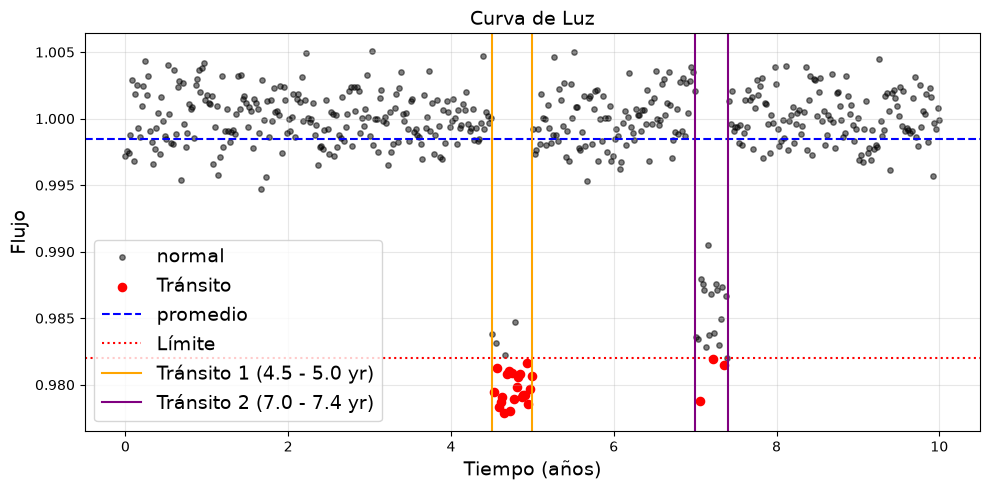

In [111]:
curvaluz(tiempo, flujo)

## Parte 2 ##

In [112]:
import numpy as np
import matplotlib.pyplot as plt

In [113]:
rng = np.random.default_rng(seed=50)

In [137]:
def imagen(X, Y, x0, y0, I0, sigma):
    """
    CREAR IMAGEN
    Cree una imagen donde cada elemento corresponde a un píxel que contiene información sobre la intensidad de la luz recibida.

    Parámetros
    ----------
    X : numpy.ndarray
        Coordenadas horizontales de la grilla espacial
    Y : numpy.ndarray
        Coordenadas verticales de la grilla espacial
    x0 : numpy.ndarray
        Posiciones centrales de las estrellas en el eje X
    y0 : numpy.ndarray
        Posiciones centrales de las estrellas en el eje Y
    I0 : numpy.ndarray
        Intensidades máximas de cada estrella
    sigma : float
        Dispersión espacial o nivel de desenfoque de las estrellas

    Salida
    ------
    distancia : numpy.ndarray
        Distancia geométrica al cuadrado desde el centro de la estrella
    I : numpy.ndarray
        Matriz de intensidad total de luz calculada
    """
    I = np.zeros_like(X)

    for i in range(len(x0)):
        distancia = (X - x0[i])**2 + (Y - y0[i])**2
        I += I0[i] * np.exp(-distancia / (2 * sigma**2))

    return I

In [138]:
ejex = np.linspace(-5, 5, 200)
ejey = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(ejex, ejey)
#Se crea una lista de 200 números que van desde el -5 hasta el 5 para la imagen y mezclamos los dos ejes para armar una tabla

In [139]:
Nestrellas = 5
x0 = rng.uniform(-5, 5, Nestrellas)
y0 = rng.uniform(-5, 5, Nestrellas)
#definimos los parametros iniciales de las 5 estrellas usando la semilla aleatoria

In [140]:
I0 = 100 + rng.uniform(-20, 20, Nestrellas)
sigma = 0.5

In [141]:
foto = imagen(X, Y, x0, y0, I0, sigma)
#llamamos a la función

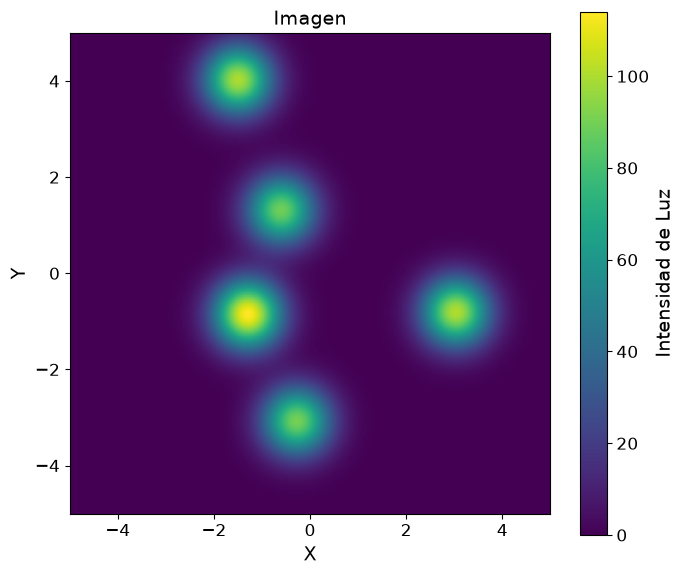

In [142]:
plt.figure(figsize=(7, 6))
plt.imshow(foto, extent=[-5, 5, -5, 5], origin='lower', cmap='viridis')
barra = plt.colorbar()
barra.set_label('Intensidad de Luz', fontsize=14)
barra.ax.tick_params(labelsize=12)
plt.xlabel('X', fontsize=14)
plt.ylabel('Y', fontsize=14)
plt.title('Imagen', fontsize=14)
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [143]:
def distancias(x0, y0):
    """
    CALCULAR DISTANCIAS
    Calcula las distancias euclidianas entre los centros de todas las estrellas.

    Parámetros
    ----------
    x0 : numpy.ndarray
        Posiciones centrales de las estrellas en el eje X
    y0 : numpy.ndarray
        Posiciones centrales de las estrellas en el eje Y

    Salida
    ------
    dx : float
        Diferencia de posición en el eje X entre dos estrellas
    dy : float
        Diferencia de posición en el eje Y entre dos estrellas
    distancias : numpy.ndarray
        Distancias euclidianas calculadas entre cada par de estrellas
    """
    total = len(x0)
    distancias = np.zeros((total, total))

    for i in range(total):
        for j in range(total):
            dx = x0[i] - x0[j]
            dy = y0[i] - y0[j]
            distancias[i, j] = np.sqrt(dx**2 + dy**2)

    return distancias

In [136]:
resultados = distancias(x0, y0)
#llamamos a la función distancias

In [151]:
orden = np.argsort(I0)
#Ordenamos los índices de I0.

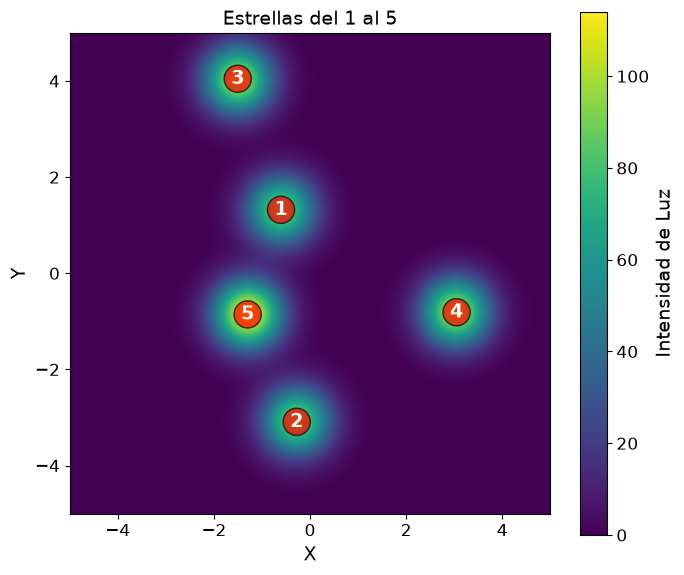

In [153]:
plt.figure(figsize=(7, 6))
plt.imshow(foto, extent=[-5, 5, -5, 5], origin='lower', cmap='viridis')
barra = plt.colorbar()
barra.set_label('Intensidad de Luz', fontsize=14)
barra.ax.tick_params(labelsize=12)
for numero, indice in enumerate(orden, start=1):
    plt.text(x0[indice], y0[indice], str(numero), color='white', 
             fontsize=14, fontweight='bold', ha='center', va='center',
             bbox=dict(boxstyle='circle,pad=0.2', facecolor='red', alpha=0.7))

plt.xlabel('X', fontsize=14)
plt.ylabel('Y', fontsize=14)
plt.title('Estrellas del 1 al 5', fontsize=14)
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [154]:
vsigma = np.linspace(0.25, 1.0, 4)
#creamos un arreglo con 4 valores distintos de sigma entre 0.25 y 1.0.

In [156]:
fotos = [imagen(X, Y, x0, y0, I0, s) for s in vsigma]
#calculamos cada foto llamando a la función 'imagen' cuatro veces como lo colocamos arriba.

In [164]:
brillomin = np.min(fotos)
brillomax = np.max(fotos)
#calculamos los valores máximos y mínimos

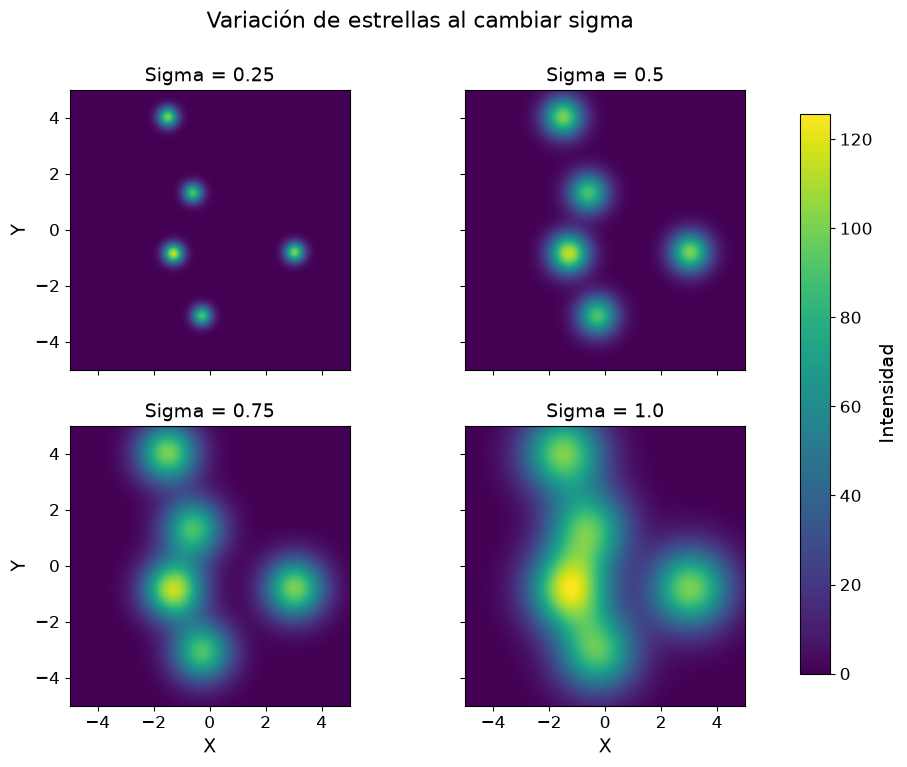

In [174]:
fig, paneles = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
#Creamos la ventana de 2 filas y 2 columnas.

for ax, s_val, f in zip(paneles.flat, vsigma, fotos):
    im = ax.imshow(f, extent=[-5, 5, -5, 5], origin='lower', cmap='viridis', 
                   vmin=brillo_min, vmax=brillo_max)
    ax.set_title('Sigma = ' + str(round(s_val, 2)), fontsize=14)
    ax.tick_params(labelsize=12)

for ax in paneles[1, :]:
    ax.set_xlabel('X', fontsize=14)
for ax in paneles[:, 0]:
    ax.set_ylabel('Y', fontsize=14)

fig.subplots_adjust(right=0.85)
cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Intensidad', fontsize=14)
cbar.ax.tick_params(labelsize=12)

plt.suptitle('Variación de estrellas al cambiar sigma', fontsize=16)

plt.show()

A medida que aumentamos el parámetro sigma (de 0.25 a 1.0), la imagen se desenfoca cada vez más, las estrellas dcomienzan a verse como puntos de luz más anchos y se empiezan a juntar como si se estuvieran fusionando.